# Introduction

Since Jan. 1, 2015, [The Washington Post](https://www.washingtonpost.com/) has been compiling a database of every fatal shooting in the US by a police officer in the line of duty. 

<center><img src=https://i.imgur.com/sX3K62b.png></center>

While there are many challenges regarding data collection and reporting, The Washington Post has been tracking more than a dozen details about each killing. This includes the race, age and gender of the deceased, whether the person was armed, and whether the victim was experiencing a mental-health crisis. The Washington Post has gathered this supplemental information from law enforcement websites, local new reports, social media, and by monitoring independent databases such as "Killed by police" and "Fatal Encounters". The Post has also conducted additional reporting in many cases.

There are 4 additional datasets: US census data on poverty rate, high school graduation rate, median household income, and racial demographics. [Source of census data](https://factfinder.census.gov/faces/nav/jsf/pages/community_facts.xhtml).

### Upgrade Plotly

Run the cell below if you are working with Google Colab

In [ ]:
%pip install --upgrade plotly

     |████████████████████████████████| 13.1MB 310kB/s 
  Found existing installation: plotly 4.4.1
    Uninstalling plotly-4.4.1:
      Successfully uninstalled plotly-4.4.1


## Import Statements

In [2]:
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

# This might be helpful:
from collections import Counter

## Notebook Presentation

In [3]:
pd.options.display.float_format = '{:,.2f}'.format

## Load the Data

In [4]:
df_hh_income = pd.read_csv('Median_Household_Income_2015.csv', encoding="windows-1252")
df_pct_poverty = pd.read_csv('Pct_People_Below_Poverty_Level.csv', encoding="windows-1252")
df_pct_completed_hs = pd.read_csv('Pct_Over_25_Completed_High_School.csv', encoding="windows-1252")
df_share_race_city = pd.read_csv('Share_of_Race_By_City.csv', encoding="windows-1252")
df_fatalities = pd.read_csv('Deaths_by_Police_US.csv', encoding="windows-1252")

# Preliminary Data Exploration

* What is the shape of the DataFrames? 
* How many rows and columns do they have?
* What are the column names?
* Are there any NaN values or duplicates?

In [5]:
print("Median Household Income:", df_hh_income.shape)
print("Poverty Percentage:", df_pct_poverty.shape)
print("High School Graduation:", df_pct_completed_hs.shape)
print("Racial Demographics:", df_share_race_city.shape)
print("Fatal Police Shootings:", df_fatalities.shape)

Median Household Income: (29322, 3)
Poverty Percentage: (29329, 3)
High School Graduation: (29329, 3)
Racial Demographics: (29268, 7)
Fatal Police Shootings: (2535, 14)


In [6]:
print("Household Income:", df_hh_income.columns.tolist())
print("Poverty:", df_pct_poverty.columns.tolist())
print("High School:", df_pct_completed_hs.columns.tolist())
print("Race:", df_share_race_city.columns.tolist())
print("Fatalities:", df_fatalities.columns.tolist())

Household Income: ['Geographic Area', 'City', 'Median Income']
Poverty: ['Geographic Area', 'City', 'poverty_rate']
High School: ['Geographic Area', 'City', 'percent_completed_hs']
Race: ['Geographic area', 'City', 'share_white', 'share_black', 'share_native_american', 'share_asian', 'share_hispanic']
Fatalities: ['id', 'name', 'date', 'manner_of_death', 'armed', 'age', 'gender', 'race', 'city', 'state', 'signs_of_mental_illness', 'threat_level', 'flee', 'body_camera']


In [7]:
datasets = {
    "Household Income": df_hh_income,
    "Poverty": df_pct_poverty,
    "High School": df_pct_completed_hs,
    "Race": df_share_race_city,
    "Fatalities": df_fatalities
}

for name, df in datasets.items():
    print(f"\n{name}")
    print(df.isnull().sum())


Household Income
Geographic Area     0
City                0
Median Income      51
dtype: int64

Poverty
Geographic Area    0
City               0
poverty_rate       0
dtype: int64

High School
Geographic Area         0
City                    0
percent_completed_hs    0
dtype: int64

Race
Geographic area          0
City                     0
share_white              0
share_black              0
share_native_american    0
share_asian              0
share_hispanic           0
dtype: int64

Fatalities
id                           0
name                         0
date                         0
manner_of_death              0
armed                        9
age                         77
gender                       0
race                       195
city                         0
state                        0
signs_of_mental_illness      0
threat_level                 0
flee                        65
body_camera                  0
dtype: int64


In [12]:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

Household Income: 0 duplicate rows
Poverty: 0 duplicate rows
High School: 0 duplicate rows
Race: 0 duplicate rows
Fatalities: 0 duplicate rows


In [13]:
for name, df in datasets.items():
    print(f"{name}: {df.shape}")
for name, df in datasets.items():
    missing = df.isnull().sum().sum()
    print(f"{name}: {missing} missing values")

Household Income: (29322, 3)
Poverty: (29329, 3)
High School: (29329, 3)
Race: (29268, 7)
Fatalities: (2535, 14)
Household Income: 51 missing values
Poverty: 0 missing values
High School: 0 missing values
Race: 0 missing values
Fatalities: 346 missing values


In [14]:
df_fatalities.head()

,id,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera
0,3,Tim Elliot,02/01/15,shot,gun,53.00,M,A,Shelton,WA,True,attack,Not fleeing,False
1,4,Lewis Lee Lembke,02/01/15,shot,gun,47.00,M,W,Aloha,OR,False,attack,Not fleeing,False
2,5,John Paul Quintero,03/01/15,shot and Tasered,unarmed,23.00,M,H,Wichita,KS,False,other,Not fleeing,False
3,8,Matthew Hoffman,04/01/15,shot,toy weapon,32.00,M,W,San Francisco,CA,True,attack,Not fleeing,False
4,9,Michael Rodriguez,04/01/15,shot,nail gun,39.00,M,H,Evans,CO,False,attack,Not fleeing,False


## Data Cleaning - Check for Missing Values and Duplicates

Consider how to deal with the NaN values. Perhaps substituting 0 is appropriate. 

In [15]:
print(df_hh_income.isnull().sum())
print(df_pct_poverty.isnull().sum())
print(df_pct_completed_hs.isnull().sum())
print(df_share_race_city.isnull().sum())
print(df_fatalities.isnull().sum())

Geographic Area     0
City                0
Median Income      51
dtype: int64
Geographic Area    0
City               0
poverty_rate       0
dtype: int64
Geographic Area         0
City                    0
percent_completed_hs    0
dtype: int64
Geographic area          0
City                     0
share_white              0
share_black              0
share_native_american    0
share_asian              0
share_hispanic           0
dtype: int64
id                           0
name                         0
date                         0
manner_of_death              0
armed                        9
age                         77
gender                       0
race                       195
city                         0
state                        0
signs_of_mental_illness      0
threat_level                 0
flee                        65
body_camera                  0
dtype: int64


In [16]:
print("Household Income:", df_hh_income.duplicated().sum())
print("Poverty:", df_pct_poverty.duplicated().sum())
print("High School:", df_pct_completed_hs.duplicated().sum())
print("Race:", df_share_race_city.duplicated().sum())
print("Fatalities:", df_fatalities.duplicated().sum())

Household Income: 0
Poverty: 0
High School: 0
Race: 0
Fatalities: 0


Household Income: (29322, 3)
Poverty: (29329, 3)
High School: (29329, 3)
Race: (29268, 7)
Fatalities: (2535, 14)
Household Income: 51 missing values
Poverty: 0 missing values
High School: 0 missing values
Race: 0 missing values
Fatalities: 346 missing values


# Chart the Poverty Rate in each US State

Create a bar chart that ranks the poverty rate from highest to lowest by US state. Which state has the highest poverty rate? Which state has the lowest poverty rate?  Bar Plot

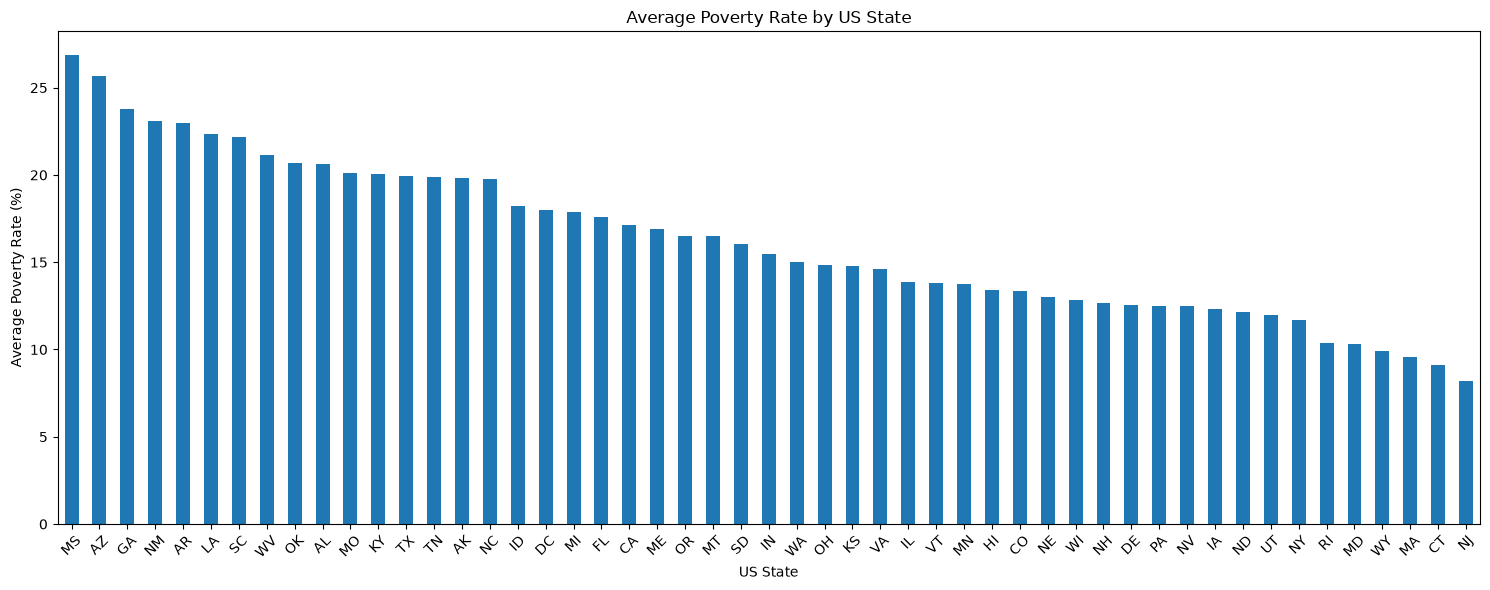

In [17]:
# Convert poverty_rate to numbers
df_pct_poverty['poverty_rate'] = pd.to_numeric(
    df_pct_poverty['poverty_rate'], errors='coerce'
)

# Calculate the average poverty rate for each state
poverty_by_state = df_pct_poverty.groupby(
    'Geographic Area'
)['poverty_rate'].mean().sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(15, 6))
poverty_by_state.plot(kind='bar')
plt.title('Average Poverty Rate by US State')
plt.xlabel('US State')
plt.ylabel('Average Poverty Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
print("State with the highest average poverty rate:")
print(poverty_by_state.idxmax(), poverty_by_state.max(), "%")

print("\nState with the lowest average poverty rate:")
print(poverty_by_state.idxmin(), poverty_by_state.min(), "%")

State with the highest average poverty rate:
MS 26.88425414364641 %

State with the lowest average poverty rate:
NJ 8.19097605893186 %


# Chart the High School Graduation Rate by US State

Show the High School Graduation Rate in ascending order of US States. Which state has the lowest high school graduation rate? Which state has the highest?

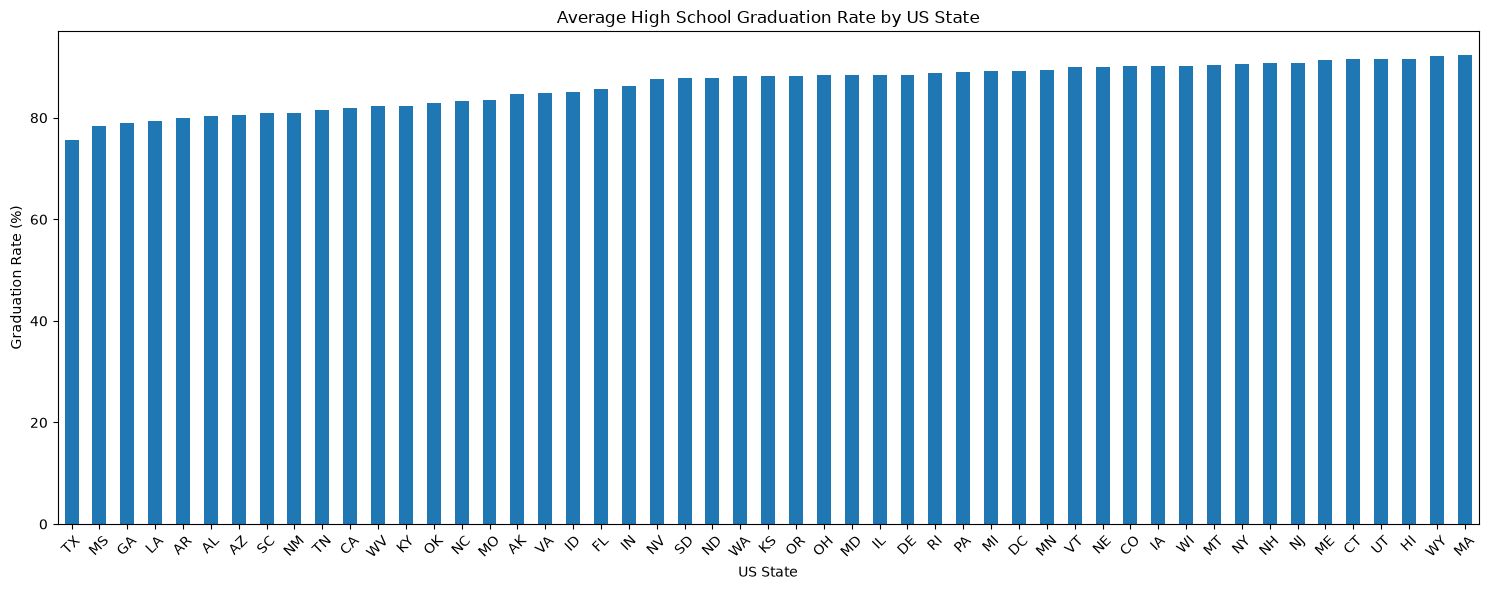

In [19]:
df_pct_completed_hs['percent_completed_hs'] = pd.to_numeric(
    df_pct_completed_hs['percent_completed_hs'], errors='coerce'
)

hs_by_state = df_pct_completed_hs.groupby(
    'Geographic Area'
)['percent_completed_hs'].mean().sort_values(ascending=True)

plt.figure(figsize=(15, 6))
hs_by_state.plot(kind='bar')
plt.title('Average High School Graduation Rate by US State')
plt.xlabel('US State')
plt.ylabel('Graduation Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
print("Lowest:", hs_by_state.idxmin(), hs_by_state.min(), "%")
print("Highest:", hs_by_state.idxmax(), hs_by_state.max(), "%")

Lowest: TX 75.69 %
Highest: MA 92.40408163265306 %


# Visualise the Relationship between Poverty Rates and High School Graduation Rates

#### Create a line chart with two y-axes to show if the rations of poverty and high school graduation move together.  

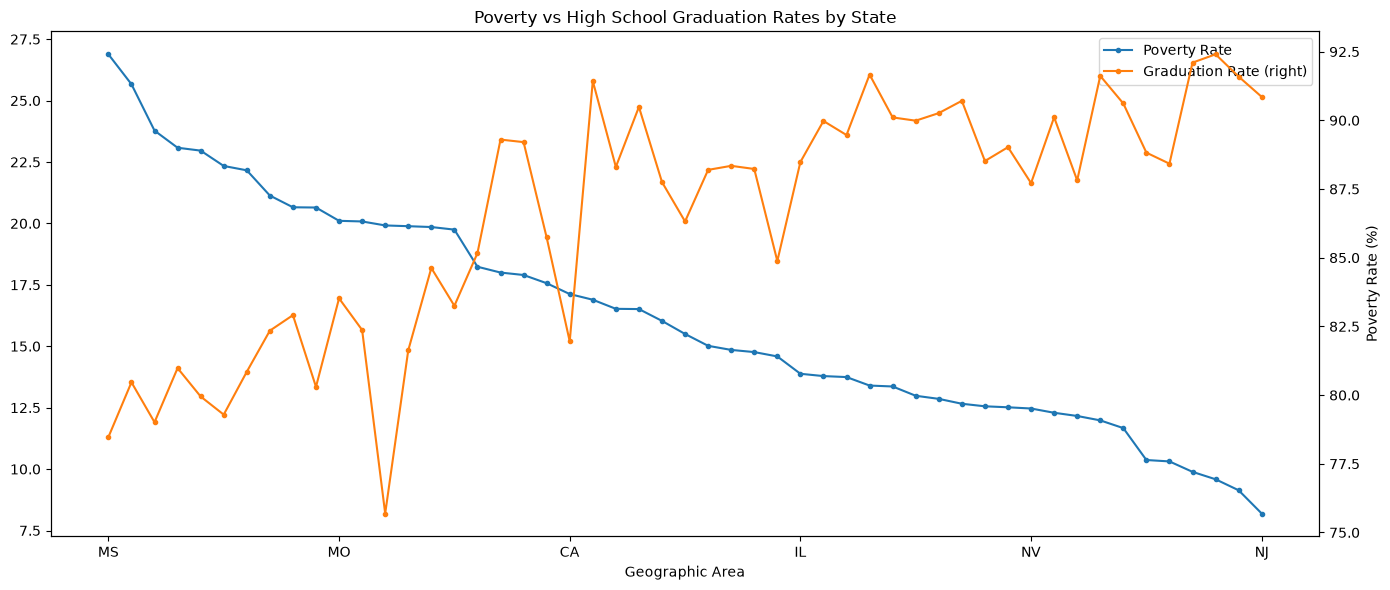

In [21]:
comparison = pd.concat(
    [
        poverty_by_state.rename('Poverty Rate'),
        hs_by_state.rename('Graduation Rate')
    ],
    axis=1
)

comparison.plot(
    kind='line',
    secondary_y='Graduation Rate',
    figsize=(14, 6),
    marker='.'
)
plt.title('Poverty vs High School Graduation Rates by State')
plt.xlabel('US State')
plt.ylabel('Poverty Rate (%)')
plt.tight_layout()
plt.show()

#### Now use a Seaborn .jointplot() with a Kernel Density Estimate (KDE) and/or scatter plot to visualise the same relationship

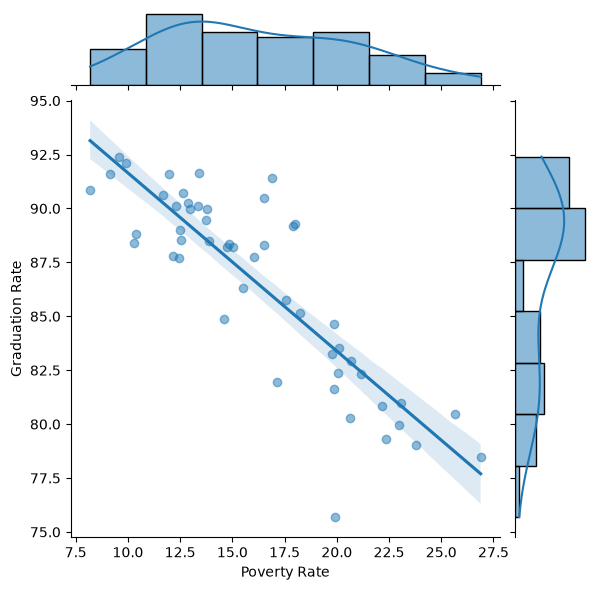

In [22]:
import seaborn as sns

sns.jointplot(
    data=comparison,
    x='Poverty Rate',
    y='Graduation Rate',
    kind='reg',
    joint_kws={'scatter_kws': {'alpha': 0.5}},
    marginal_kws={'fill': True}
)
plt.show()

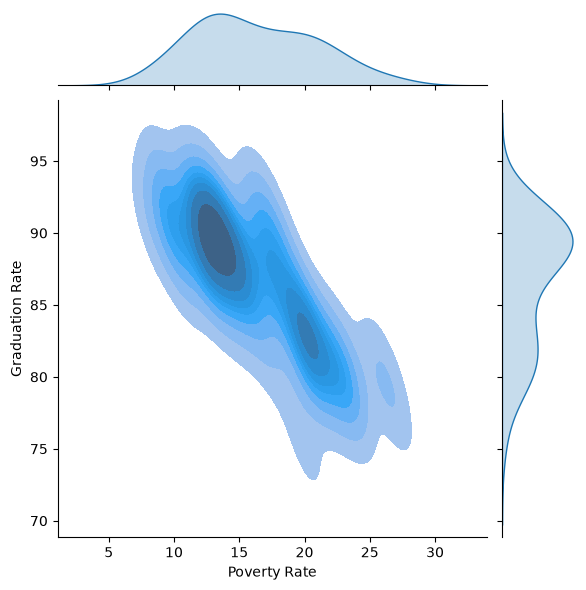

In [23]:
sns.jointplot(
    data=comparison,
    x='Poverty Rate',
    y='Graduation Rate',
    kind='kde',
    fill=True
)
plt.show()

#### Seaborn's `.lmplot()` or `.regplot()` to show a linear regression between the poverty ratio and the high school graduation ratio. 

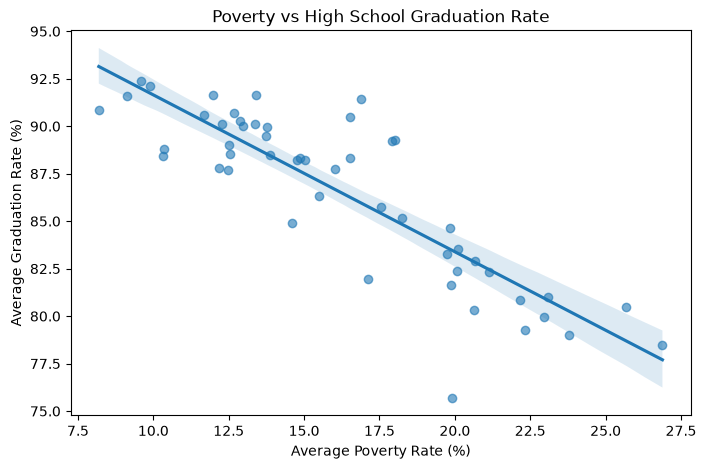

In [24]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=comparison,
    x='Poverty Rate',
    y='Graduation Rate',
    scatter_kws={'alpha': 0.6}
)

plt.title('Poverty vs High School Graduation Rate')
plt.xlabel('Average Poverty Rate (%)')
plt.ylabel('Average Graduation Rate (%)')
plt.show()

# Create a Bar Chart with Subsections Showing the Racial Makeup of Each US State

Visualise the share of the white, black, hispanic, asian and native american population in each US State using a bar chart with sub sections. 

In [25]:
df_share_race_city.head()

,Geographic area,City,share_white,share_black,share_native_american,share_asian,share_hispanic
0,AL,Abanda CDP,67.2,30.2,0,0,1.6
1,AL,Abbeville city,54.4,41.4,0.1,1,3.1
2,AL,Adamsville city,52.3,44.9,0.5,0.3,2.3
3,AL,Addison town,99.1,0.1,0,0.1,0.4
4,AL,Akron town,13.2,86.5,0,0,0.3


In [28]:
race_columns = [
    'share_white',
    'share_black',
    'share_hispanic',
    'share_asian',
    'share_native_american'
]

df_share_race_city[race_columns] = df_share_race_city[race_columns].apply(
    pd.to_numeric, errors='coerce'
)

In [26]:
df_share_race_city.columns

Index(['Geographic area', 'City', 'share_white', 'share_black',
       'share_native_american', 'share_asian', 'share_hispanic'],
      dtype='str')

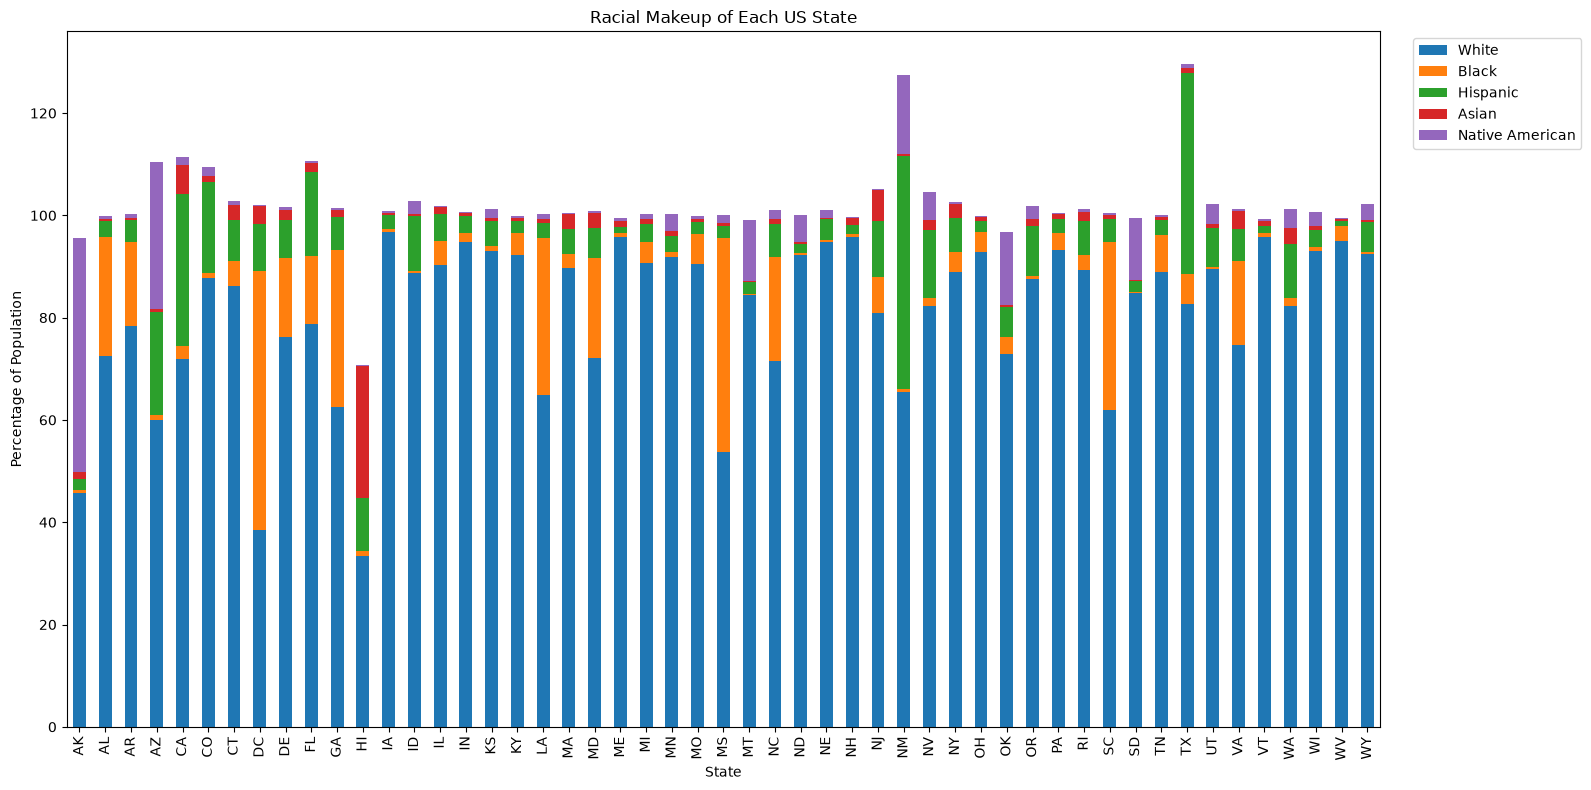

In [29]:
df_share_race_city.groupby('Geographic area')[
    ['share_white', 'share_black', 'share_hispanic',
     'share_asian', 'share_native_american']
].mean().plot(
    kind='bar',
    stacked=True,
    figsize=(16, 8)
)

plt.title('Racial Makeup of Each US State')
plt.xlabel('State')
plt.ylabel('Percentage of Population')
plt.legend(
    ['White', 'Black', 'Hispanic', 'Asian', 'Native American'],
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Create Donut Chart by of People Killed by Race

Hint: Use `.value_counts()`

In [30]:
df_fatalities['race'].value_counts()

race
W    1201
B     618
H     423
A      39
N      31
O      28
Name: count, dtype: int64

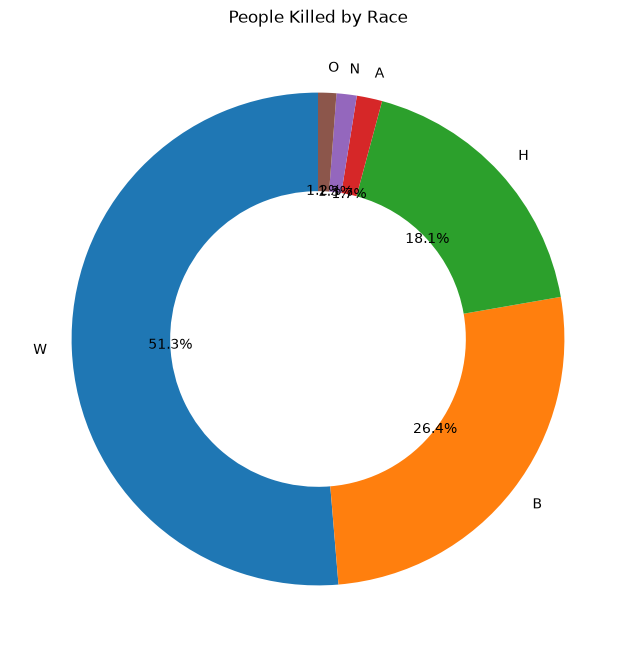

In [31]:
race_counts = df_fatalities['race'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    race_counts,
    labels=race_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title('People Killed by Race')
plt.show()

# Create a Chart Comparing the Total Number of Deaths of Men and Women

Use `df_fatalities` to illustrate how many more men are killed compared to women. 

In [32]:
df_fatalities['gender'].value_counts()

gender
M    2428
F     107
Name: count, dtype: int64

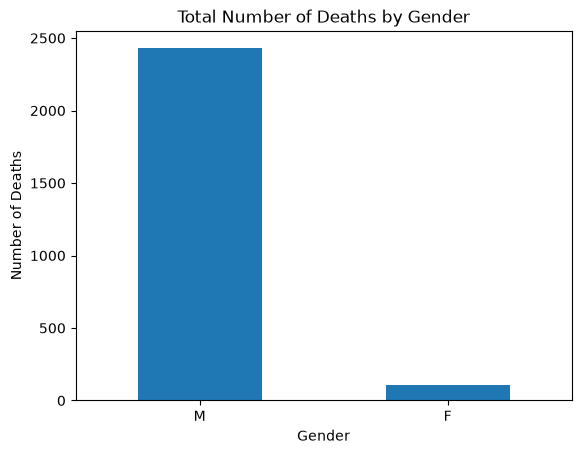

In [33]:
df_fatalities['gender'].value_counts().plot(kind='bar')

plt.title('Total Number of Deaths by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Deaths')
plt.xticks(rotation=0)
plt.show()

# Create a Box Plot Showing the Age and Manner of Death

Break out the data by gender using `df_fatalities`. Is there a difference between men and women in the manner of death? 

In [34]:
df_fatalities[['age', 'gender', 'manner_of_death']].head()

,age,gender,manner_of_death
0,53.00,M,shot
1,47.00,M,shot
2,23.00,M,shot and Tasered
3,32.00,M,shot
4,39.00,M,shot


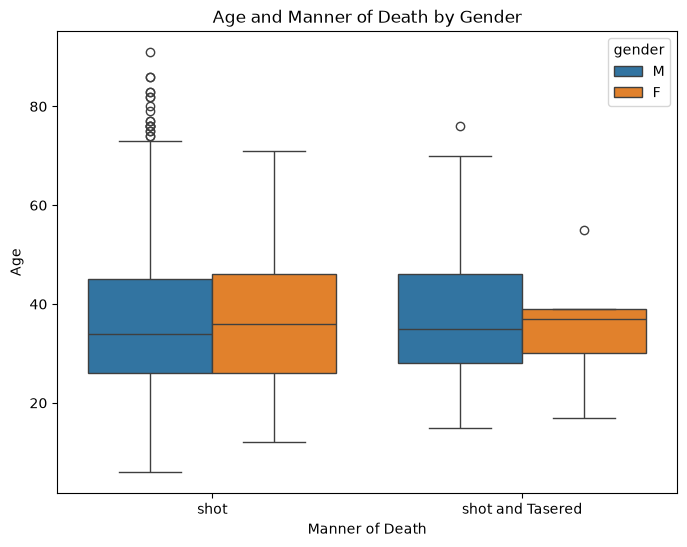

In [35]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df_fatalities,
    x='manner_of_death',
    y='age',
    hue='gender'
)

plt.title('Age and Manner of Death by Gender')
plt.xlabel('Manner of Death')
plt.ylabel('Age')
plt.show()

In [36]:
df_fatalities.groupby(
    ['gender', 'manner_of_death']
)['age'].median()

gender  manner_of_death 
F       shot               36.00
        shot and Tasered   37.00
M       shot               34.00
        shot and Tasered   35.00
Name: age, dtype: float64

# Were People Armed? 

In what percentage of police killings were people armed? Create chart that show what kind of weapon (if any) the deceased was carrying. How many of the people killed by police were armed with guns versus unarmed? 

In [37]:
df_fatalities['armed'].value_counts()

armed
gun                        1398
knife                       373
vehicle                     177
unarmed                     171
undetermined                117
                           ... 
air conditioner               1
pole and knife                1
baseball bat and bottle       1
fireworks                     1
pen                           1
Name: count, Length: 68, dtype: int64

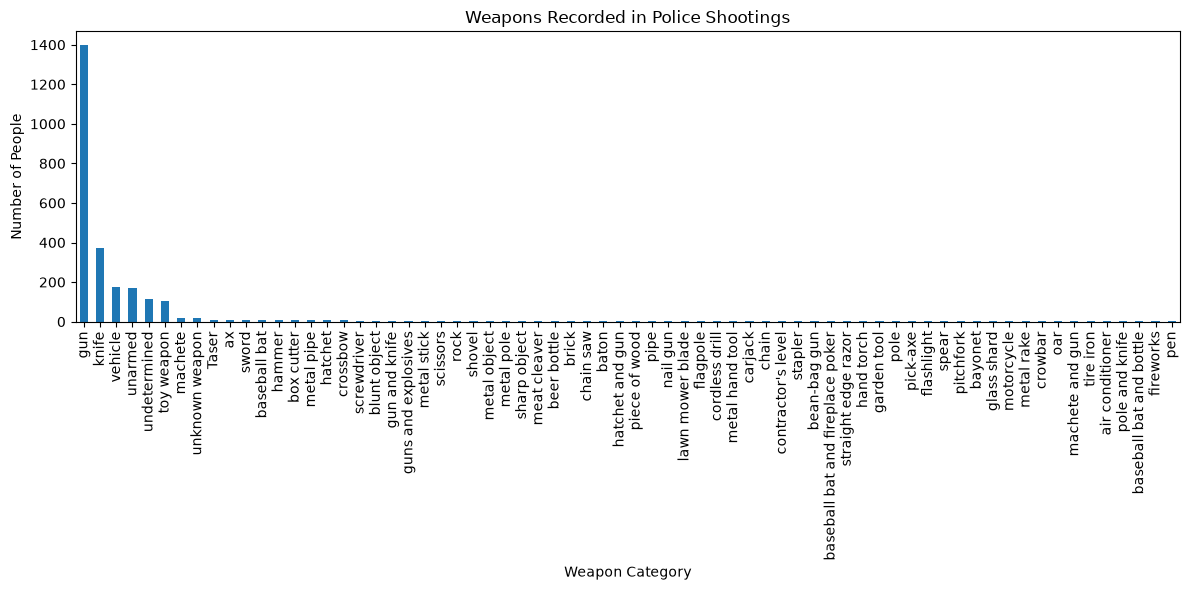

In [38]:
df_fatalities['armed'].value_counts().plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Weapons Recorded in Police Shootings')
plt.xlabel('Weapon Category')
plt.ylabel('Number of People')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [39]:
armed_counts = df_fatalities['armed'].value_counts()

armed_counts

armed
gun                        1398
knife                       373
vehicle                     177
unarmed                     171
undetermined                117
                           ... 
air conditioner               1
pole and knife                1
baseball bat and bottle       1
fireworks                     1
pen                           1
Name: count, Length: 68, dtype: int64

In [40]:
total_records = df_fatalities['armed'].notna().sum()
armed_percentage = (
    df_fatalities['armed'].notna() &
    (df_fatalities['armed'] != 'unarmed')
).sum() / total_records * 100

gun_count = (df_fatalities['armed'] == 'gun').sum()
unarmed_count = (df_fatalities['armed'] == 'unarmed').sum()

print(f"Recorded as armed: {armed_percentage:.2f}%")
print(f"Armed with a gun: {gun_count}")
print(f"Unarmed: {unarmed_count}")

Recorded as armed: 93.23%
Armed with a gun: 1398
Unarmed: 171


# How Old Were the People Killed?

Work out what percentage of people killed were under 25 years old.  

In [42]:
under_25 = (df_fatalities['age'] < 25).sum()
total_with_age = df_fatalities['age'].notna().sum()

percentage_under_25 = under_25 / total_with_age * 100

print(f"Percentage under 25: {percentage_under_25:.2f}%")

Percentage under 25: 18.31%


Create a histogram and KDE plot that shows the distribution of ages of the people killed by police. 

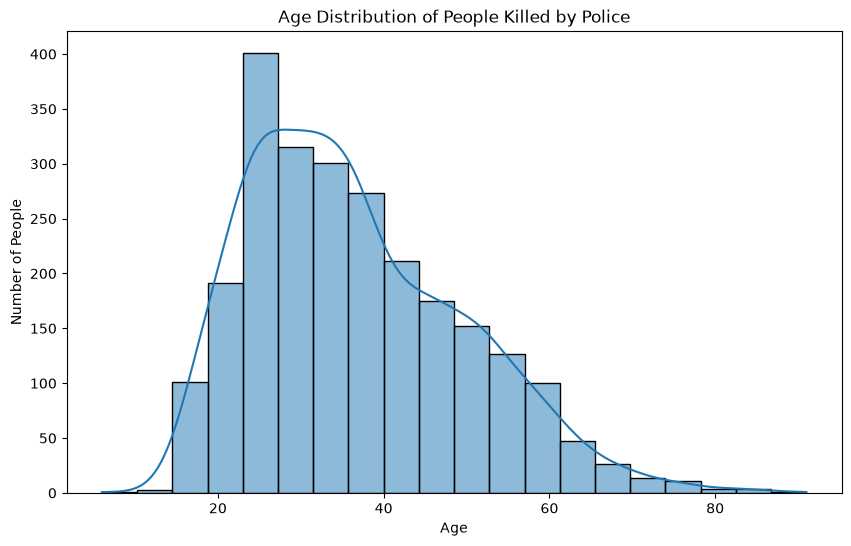

In [43]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_fatalities,
    x='age',
    bins=20,
    kde=True
)

plt.title('Age Distribution of People Killed by Police')
plt.xlabel('Age')
plt.ylabel('Number of People')
plt.show()

Create a seperate KDE plot for each race. Is there a difference between the distributions? 

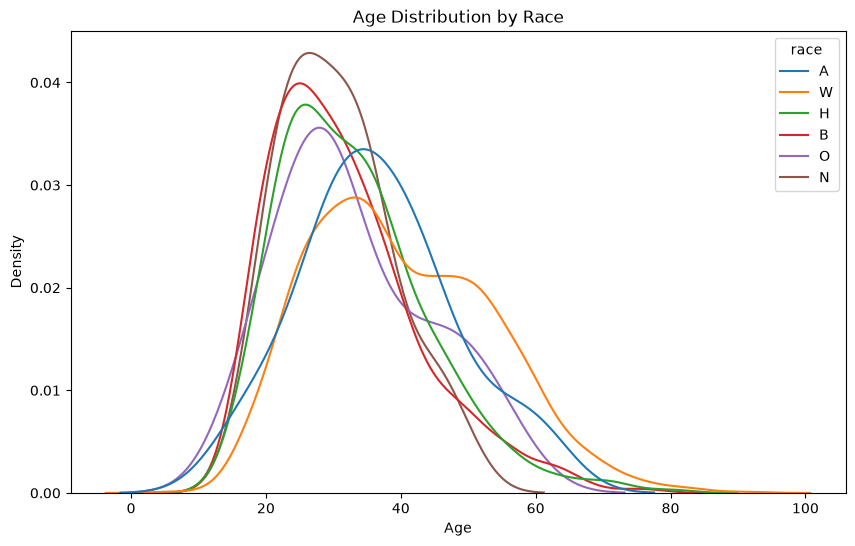

In [44]:
plt.figure(figsize=(10, 6))

sns.kdeplot(
    data=df_fatalities,
    x='age',
    hue='race',
    fill=False,
    common_norm=False
)

plt.title('Age Distribution by Race')
plt.xlabel('Age')
plt.ylabel('Density')
plt.show()

# Race of People Killed

Create a chart that shows the total number of people killed by race. 

In [45]:
df_fatalities['race'].value_counts()

race
W    1201
B     618
H     423
A      39
N      31
O      28
Name: count, dtype: int64

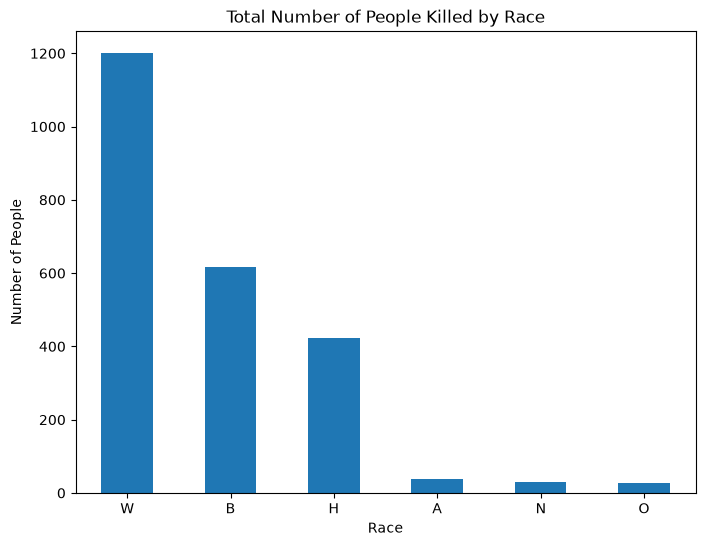

In [46]:
df_fatalities['race'].value_counts().plot(
    kind='bar',
    figsize=(8, 6)
)

plt.title('Total Number of People Killed by Race')
plt.xlabel('Race')
plt.ylabel('Number of People')
plt.xticks(rotation=0)
plt.show()

# Mental Illness and Police Killings

What percentage of people killed by police have been diagnosed with a mental illness?

In [47]:
df_fatalities['signs_of_mental_illness'].value_counts()

signs_of_mental_illness
False    1902
True      633
Name: count, dtype: int64

In [48]:
mental_illness_yes = (
    df_fatalities['signs_of_mental_illness'] == True
).sum()

total_known = df_fatalities['signs_of_mental_illness'].notna().sum()

percentage = mental_illness_yes / total_known * 100

print(f"Percentage with signs of mental illness: {percentage:.2f}%")

Percentage with signs of mental illness: 24.97%


# In Which Cities Do the Most Police Killings Take Place?

Create a chart ranking the top 10 cities with the most police killings. Which cities are the most dangerous?  

In [49]:
top_cities = df_fatalities['city'].value_counts().head(10)

print(top_cities)

city
Los Angeles    39
Phoenix        31
Houston        27
Chicago        25
Las Vegas      21
San Antonio    20
Columbus       19
Austin         18
Miami          18
St. Louis      15
Name: count, dtype: int64


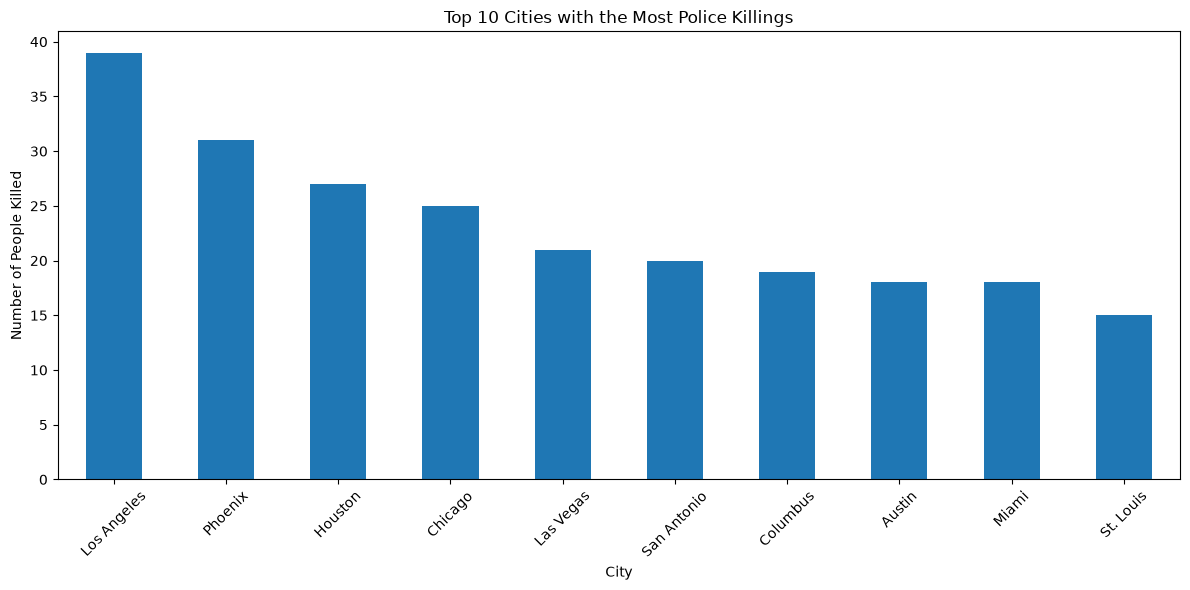

In [50]:
plt.figure(figsize=(12, 6))

top_cities.plot(kind='bar')

plt.title('Top 10 Cities with the Most Police Killings')
plt.xlabel('City')
plt.ylabel('Number of People Killed')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Rate of Death by Race

Find the share of each race in the top 10 cities. Contrast this with the top 10 cities of police killings to work out the rate at which people are killed by race for each city. 

In [51]:
top_cities = df_fatalities['city'].value_counts().head(10)

print(top_cities)

city
Los Angeles    39
Phoenix        31
Houston        27
Chicago        25
Las Vegas      21
San Antonio    20
Columbus       19
Austin         18
Miami          18
St. Louis      15
Name: count, dtype: int64


In [52]:
top_city_names = top_cities.index

df_top_cities = df_fatalities[
    df_fatalities['city'].isin(top_city_names)
].copy()

df_top_cities.head()

,id,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera
12,22,Hashim Hanif Ibn Abdul-Rasheed,07/01/15,shot,knife,41.00,M,B,Columbus,OH,True,other,Not fleeing,False
40,75,Pablo Meza,17/01/15,shot,gun,24.00,M,H,Los Angeles,CA,False,attack,Not fleeing,False
48,90,Isaac Holmes,21/01/15,shot,gun,19.00,M,B,St. Louis,MO,False,attack,Not fleeing,False
52,336,Robert Francis Mesch,23/01/15,shot,gun,61.00,M,W,Austin,TX,True,attack,Not fleeing,False
64,348,Nicolas Leland Tewa,27/01/15,shot,vehicle,26.00,M,N,Phoenix,AZ,False,other,Not fleeing,False


In [53]:
deaths_by_city_race = (
    df_top_cities.groupby(['city', 'state', 'race'])
    .size()
    .reset_index(name='deaths')
)

deaths_by_city_race.head(10)

,city,state,race,deaths
0,Austin,AR,W,1
1,Austin,MN,W,1
2,Austin,TX,B,3
3,Austin,TX,H,2
4,Austin,TX,W,11
5,Chicago,IL,B,21
6,Chicago,IL,H,1
7,Chicago,IL,W,2
8,Columbus,MS,B,1
9,Columbus,MS,W,1


In [54]:
df_share_race_city.head()

,Geographic area,City,share_white,share_black,share_native_american,share_asian,share_hispanic
0,AL,Abanda CDP,67.20,30.20,0.00,0.00,1.60
1,AL,Abbeville city,54.40,41.40,0.10,1.00,3.10
2,AL,Adamsville city,52.30,44.90,0.50,0.30,2.30
3,AL,Addison town,99.10,0.10,0.00,0.10,0.40
4,AL,Akron town,13.20,86.50,0.00,0.00,0.30


# Create a Choropleth Map of Police Killings by US State

Which states are the most dangerous? Compare your map with your previous chart. Are these the same states with high degrees of poverty? 

In [55]:
state_deaths = (
    df_fatalities['state']
    .value_counts()
    .reset_index()
)

state_deaths.columns = ['state', 'killings']

state_deaths.head()

,state,killings
0,CA,424
1,TX,225
2,FL,154
3,AZ,118
4,OH,79


In [56]:
import plotly.express as px

fig = px.choropleth(
    state_deaths,
    locations='state',
    locationmode='USA-states',
    color='killings',
    scope='usa',
    color_continuous_scale='Reds',
    title='Recorded Police Killings by US State'
)

fig.show()

In [58]:
deaths_by_city_race = df_top_cities.groupby(
    ['city', 'race']
).size().reset_index(name='deaths')

deaths_by_city_race.head(10)

,city,race,deaths
0,Austin,B,3
1,Austin,H,2
2,Austin,W,13
3,Chicago,B,21
4,Chicago,H,1
5,Chicago,W,2
6,Columbus,B,11
7,Columbus,O,1
8,Columbus,W,6
9,Houston,A,1


In [59]:
state_deaths = df_fatalities['state'].value_counts().reset_index()
state_deaths.columns = ['state', 'killings']

state_deaths.head()

,state,killings
0,CA,424
1,TX,225
2,FL,154
3,AZ,118
4,OH,79


In [60]:
import plotly.express as px

fig = px.choropleth(
    state_deaths,
    locations='state',
    locationmode='USA-states',
    color='killings',
    scope='usa',
    color_continuous_scale='Reds',
    title='Recorded Police Killings by US State'
)

fig.show()

# Number of Police Killings Over Time

Analyse the Number of Police Killings over Time. Is there a trend in the data? 

In [61]:
df_fatalities['date'] = pd.to_datetime(df_fatalities['date'])

df_fatalities[['date']].head()

/var/folders/kt/tjhwq0n53jv_qyk4l30p9ybc0000gp/T/ipykernel_13196/3830550359.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_fatalities['date'] = pd.to_datetime(df_fatalities['date'])


,date
0,2015-02-01
1,2015-02-01
2,2015-03-01
3,2015-04-01
4,2015-04-01


In [62]:
killings_over_time = df_fatalities.groupby('date').size()

killings_over_time.head()

date
2015-01-03    3
2015-01-04    2
2015-01-06    1
2015-01-07    2
2015-01-08    2
dtype: int64

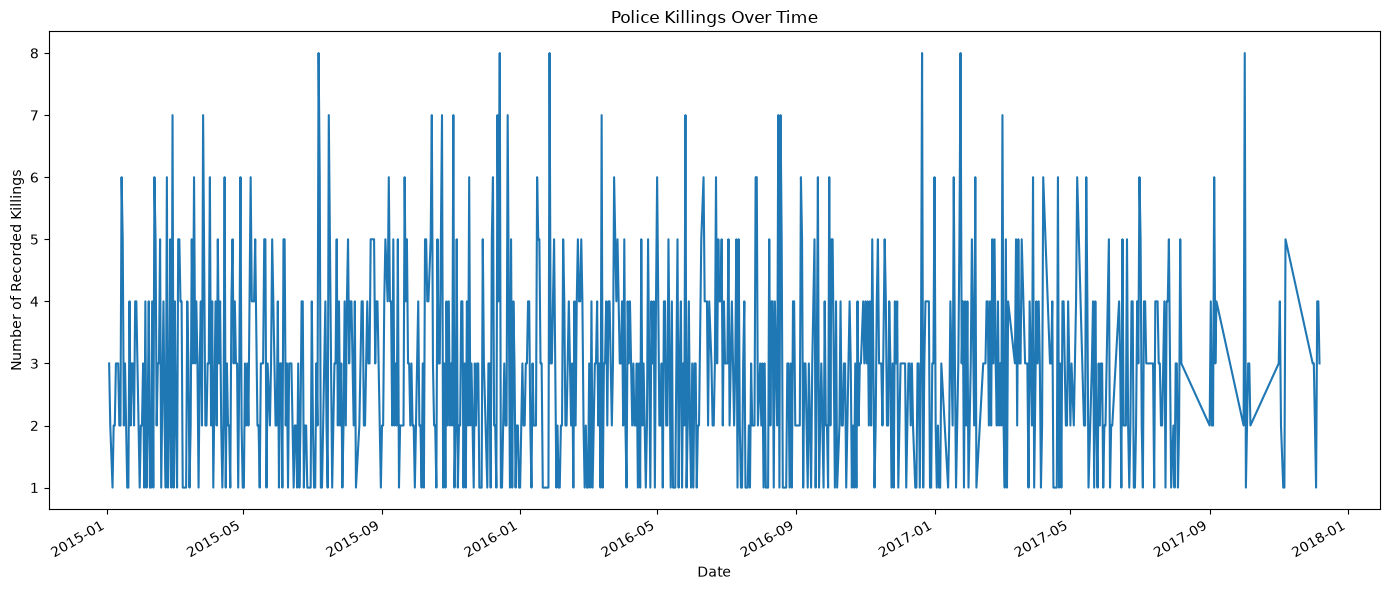

In [63]:
plt.figure(figsize=(14, 6))

killings_over_time.plot()

plt.title('Police Killings Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Recorded Killings')
plt.tight_layout()
plt.show()

# Epilogue

Now that you have analysed the data yourself, read [The Washington Post's analysis here](https://www.washingtonpost.com/graphics/investigations/police-shootings-database/).

In [ ]:
""" 
Epilogue

Through this project, I explored data on people killed by police in the United States and used Python libraries such as Pandas, Matplotlib, Seaborn, and Plotly to analyze and visualize the data.

I examined patterns involving age, race, gender, mental illness, location, poverty, and changes over time. The visualizations helped me understand how data analysis can reveal patterns that may not be obvious from raw data.

This project also taught me that data needs to be interpreted carefully. The number of recorded killings alone does not explain why they happened or account for differences in population size. Data analysis can help us ask meaningful questions, but we must consider the limitations of the dataset before drawing conclusions.

Overall, this project helped me practice data cleaning, exploratory data analysis, and visualization while understanding how Python can be used to explore real-world social issues."""